In [30]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler


In [31]:
# 데이터 전처리 완료
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [32]:
# 학습데이터 , 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)

In [23]:
train_data

array([25.6, 22. , 22. , 22.7,  8.4, 39. , 32.8, 43. , 22. , 27.5, 26.5,
       18.7, 39. , 20. , 19. , 23. , 21. , 21.3, 24. , 43.5, 44. , 23.5,
       28. , 22.5, 22. , 16.2, 40. , 17.4, 40. , 39. , 15. , 27.5, 21. ,
       37. , 27.5, 28.7, 43. , 21. , 19.6, 13.7, 40. , 37. ])

In [33]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
test_data[:3] # 2차원 배열로 변경해야됨

array([[39. ],
       [27.5],
       [40. ]])

In [34]:


# 데이터 학습
knr = KNeighborsRegressor()
knr.fit(train_data,train_label)
# 데이터 예측
result = knr.predict(test_data)
print('예측무게 : ',result)
# 정확도,오차
score = knr.score(train_data,train_label)
score2 = knr.score(test_data,test_label)
print('정확도1 : ',score)
print('정확도2 : ',score2)

예측무게 :  [752.  255.6 834.   97.  129.  984.   66.7 834.  834.  136.  124.  117.
  85.3  85.3]
정확도1 :  0.9771470642678116
정확도2 :  0.9745869590270976


In [40]:
# 오차범위
mae = mean_absolute_error(test_label,result)
print('오차범위 : ',mae)

오차범위 :  39.64999999999999


예측무게 :  [984.]


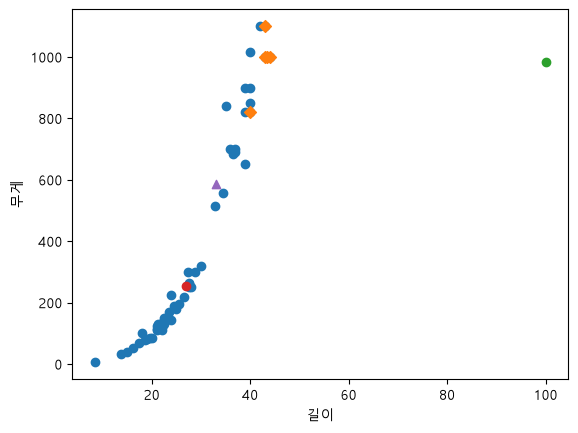

In [56]:
# 길이를 입력받아, 무게를 예측하시오.
# 길이를 입려갛세요.(예:27)
# 예측무게
input1 = input('길이를 입력하시오 예)27 ') # 27 - 255.6
input1 = float(input1)
predict = knr.predict([[input1]])
print('예측무게 : ',predict)
distances, indexes = knr.kneighbors([[input1]])
indexes

plt.scatter(perch_length,perch_weight)
plt.scatter(train_data[indexes],train_label[indexes],marker='D')
plt.scatter(input1,predict)
plt.scatter(27,255.6)
plt.scatter(33,586,marker='^')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

array([[27, 32, 35, 41, 33]])